# 11 — Min / max targets and the feature table

*Extension: min / max price · code: `src/sp500/range_data.py`*

Builds the table used by every range model: 72 features known at the close of day *t*, and the targets *highest high* and *lowest low* over the next 5 and 21 trading days.

← previous: [`10_candle_resampling.ipynb`](10_candle_resampling.ipynb) · next: [`12_xgboost.ipynb`](12_xgboost.ipynb) →

In [1]:
import sys, warnings
from pathlib import Path

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
sys.path[:0] = [str(ROOT / "src"), str(ROOT)]   # project package + root scripts

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, Markdown, display

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 160)
plt.rcParams.update({"figure.dpi": 100, "axes.titleweight": "bold", "font.size": 10})

In [2]:
from sp500.config import DATA_PROCESSED
from sp500.range_data import build_range_table, feature_columns, RANGE_HORIZONS

daily = pd.read_parquet(DATA_PROCESSED / "sp500_daily.parquet")
table = build_range_table(daily)
feats = feature_columns(table)
print(f"{len(table):,} rows ({table.index.min().date()} -> {table.index.max().date()}), {len(feats)} features")

16,186 rows (1962-07-02 -> 2026-10-23), 72 features


## 1. Targets

$$up_h = \log\frac{\max(high_{t+1..t+h})}{close_t}, \qquad down_h = \log\frac{\min(low_{t+1..t+h})}{close_t}$$

so **max price** = close · e<sup>up</sup> and **min price** = close · e<sup>down</sup>.

In [3]:
t = table[[f"{k}_{h}" for h in RANGE_HORIZONS for k in ("up", "down")]].dropna()
(t * 100).describe(percentiles=[.1, .5, .9]).T.style.format("{:.2f}")

,count,mean,std,min,10%,50%,90%,max
up_5,15881.00,1.61,1.45,-5.62,0.22,1.29,3.38,17.49
down_5,15881.00,-1.64,1.87,-37.36,-3.73,-1.12,-0.09,4.67
up_21,15881.00,3.38,2.60,-3.07,0.66,2.89,6.64,25.22
down_21,15881.00,-3.39,3.88,-42.05,-7.66,-2.32,-0.31,4.67


## 2. Volatility scaling

A 2% weekly range is huge in 2017 and tiny in 2008. Models therefore learn `target / σ` with σ = Parkinson 21-day volatility × √(h/252) (known at *t*), and predictions are multiplied back by today's σ.

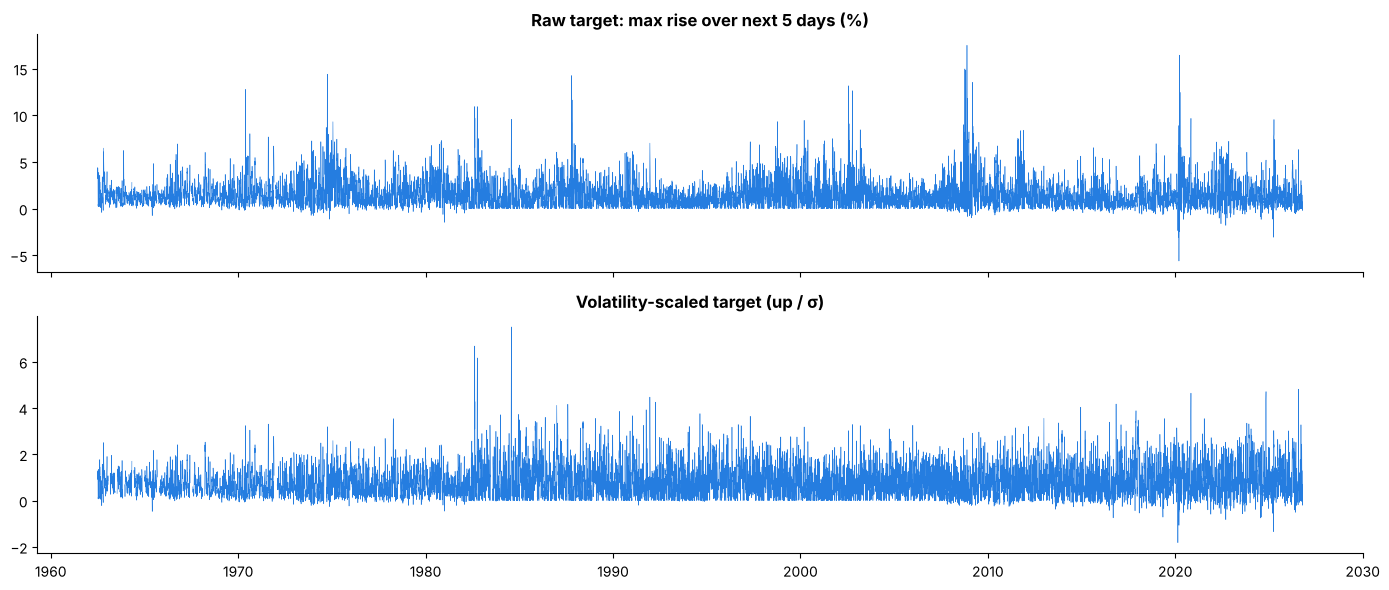

std of the yearly median:  raw 0.372 | scaled 0.127


In [4]:
fig, axes = plt.subplots(2, 1, figsize=(14, 6), sharex=True)
y = table["up_5"] * 100
axes[0].plot(y.index, y, lw=0.4, color="#257de0"); axes[0].set_title("Raw target: max rise over next 5 days (%)")
axes[1].plot(y.index, table["up_5"] / table["sigma_5"], lw=0.4, color="#257de0"); axes[1].set_title("Volatility-scaled target (up / σ)")
for ax in axes: ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.show()
print("std of the yearly median:  raw", round(y.groupby(y.index.year).median().std(), 3),
      "| scaled", round((table["up_5"] / table["sigma_5"]).groupby(y.index.year).median().std(), 3))

## 3. Features

In [5]:
groups = {
    "regime features (main model)": [f for f in feats if f in ("ret_1d", "mom_1m", "mom_3m", "mom_12m", "dist_ma50", "dist_ma200", "drawdown",
                                       "below_peak_regime", "rv_21d", "rv_63d", "parkinson_21d", "rv_vs_5y_p80", "gap_open")],
    "range / ATR / candle shape": [f for f in feats if f.startswith(("atr", "range_", "past_", "close_pos", "upper_", "lower_", "body", "vol_ratio", "dow", "month"))],
    "candlestick patterns": [f for f in feats if f.startswith(("pat_", "pattern_"))],
    "weekly / monthly candles": [f for f in feats if f.startswith(("w_", "m_"))],
}
pd.DataFrame({"n": {k: len(v) for k, v in groups.items()}, "features": {k: ", ".join(v) for k, v in groups.items()}})

,n,features
regime features (main model),12,"mom_1m, mom_3m, mom_12m, dist_ma50, dist_ma200..."
range / ATR / candle shape,15,"atr_14_pct, range_1d, range_5d, range_21d, pas..."
candlestick patterns,27,"pat_doji, pat_hammer, pat_shooting_star, pat_b..."
weekly / monthly candles,18,"w_prev_range, w_prev_body, w_range_avg8, w_pat..."


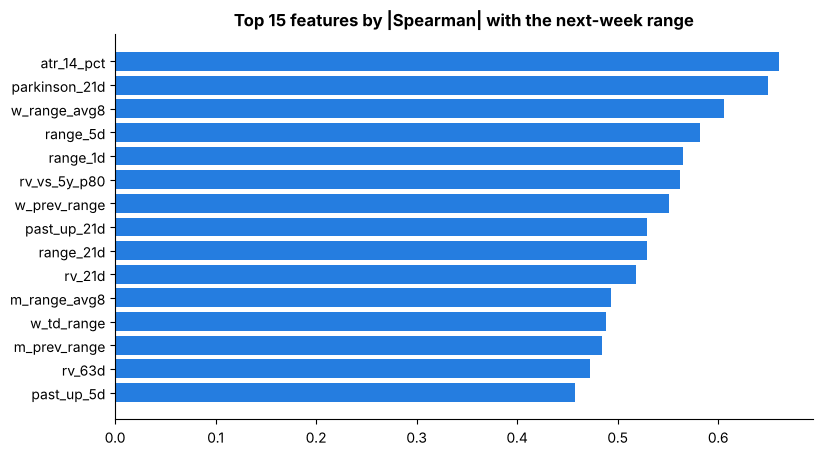

In [6]:
rho = table[feats].corrwith(table["up_5"] - table["down_5"], method="spearman").dropna()
top = rho.abs().sort_values(ascending=False).head(15).index
fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(top[::-1], rho[top[::-1]], color="#257de0")
ax.set_title("Top 15 features by |Spearman| with the next-week range")
ax.spines[["top", "right"]].set_visible(False); plt.show()

## 4. Look-ahead check and save

In [7]:
cut = "2015-06-17"
t2 = build_range_table(daily.loc[:cut])
d = (table.loc[:cut, feats].iloc[-300:] - t2.loc[:cut, feats].iloc[-300:]).abs().max()
assert (d.fillna(0) < 1e-9).all(), d[d > 1e-9]
print("OK: every feature identical when rebuilt on data cut at", cut)
table.to_parquet(DATA_PROCESSED / "range_table.parquet")
print("saved data/processed/range_table.parquet")

OK: every feature identical when rebuilt on data cut at 2015-06-17
saved data/processed/range_table.parquet
